# 06 — Feature validation and role audit

This notebook validates the 99 point-in-time-safe features in the enriched daily panel. **It does not drop features.** Instead, it annotates each feature for possible use as:

- a direct predictor,
- a segmentation or bifurcation variable,
- a context/control/interaction variable, or
- a retained feature that needs caution.

Validation is broader than a hypothesis-test p-value. With roughly 3.5 million labels, tiny and economically irrelevant effects can be statistically significant, while useful segmentation variables can have weak pooled relationships. The audit therefore emphasizes effect size, within-stock behavior, annual stability, nonlinear separation, and heterogeneity in the error of a historical-auction baseline.

In [1]:
from pathlib import Path
from math import erfc, sqrt
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 140)
pd.set_option("display.max_rows", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 7), "figure.dpi": 120})

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "blackrock_data").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate blackrock_data.")

SOURCE = PROJECT_ROOT / "outputs" / "eda" / "05_feature_engineering"
PANEL = SOURCE / "enriched_daily_panel.parquet"
CATALOG = SOURCE / "approved_enriched_daily_features.csv"
OUT = PROJECT_ROOT / "outputs" / "eda" / "06_feature_validation"
OUT.mkdir(parents=True, exist_ok=True)
if not PANEL.exists() or not CATALOG.exists():
    raise FileNotFoundError("Run Notebook 05 before Notebook 06.")

con = duckdb.connect()
con.execute("PRAGMA threads=4")

def sql(query, params=None):
    return con.execute(query, params or []).df()

catalog = pd.read_csv(CATALOG)
FEATURES = catalog["variable"].tolist()
print(f"Features retained for validation: {len(FEATURES)}")
print(f"Panel: {PANEL}")

Features retained for validation: 99
Panel: /Users/aramesh/Documents/Fall 2026/Capstone/outputs/eda/05_feature_engineering/enriched_daily_panel.parquet


## Validation policy

The main outcome is `log1p(auction_volume)`. The simple reference forecast is `log1p(median20_auction_volume)`. A feature may be useful for bifurcation when it separates the target level or the absolute error of this reference forecast, even if it has little pooled correlation with the target.

Approximate p-values below treat sampled stock-days as independent and are therefore optimistic because observations share dates and securities. They are reported for completeness, but role assignments use effect sizes and stability—not p-values alone.

In [2]:
BOOLEAN_FEATURES = [
    "auction_spike_lag1", "is_monday", "is_friday",
    "is_first_trading_day_month", "is_last_trading_day_month",
    "is_last_3_trading_days_month", "is_last_5_trading_days_month",
    "is_last_trading_day_quarter", "is_last_3_trading_days_quarter",
    "is_last_5_trading_days_quarter", "is_last_trading_day_year",
    "monthly_options_expiry", "quarterly_options_expiry",
    "after_long_market_gap", "before_long_market_gap", "is_early_close",
    "early_close_month_end_window", "expiry_month_end_window",
    "lag1_dividend_flag", "lag1_distribution_flag", "lag1_price_adjustment_flag",
]
CATEGORICAL_FEATURES = ["month", "day_of_week", "ff12_code", "size_decile", "liquidity_decile"]
ORDERED_OR_CONTINUOUS = [f for f in FEATURES if f not in CATEGORICAL_FEATURES]

assert set(BOOLEAN_FEATURES).issubset(FEATURES)
assert set(CATEGORICAL_FEATURES).issubset(FEATURES)
print(f"Ordered/continuous or binary: {len(ORDERED_OR_CONTINUOUS)}")
print(f"Explicit categorical: {len(CATEGORICAL_FEATURES)}")

Ordered/continuous or binary: 94
Explicit categorical: 5


## Fixed analytical sample

In [3]:
quoted_features = ",\n       ".join(f'"{f}"' for f in FEATURES)
sample = sql(f"""
SELECT date, year, permno,
       log1p_auction_volume AS target,
       ln(1 + median20_auction_volume) AS baseline_prediction,
       {quoted_features}
FROM read_parquet('{PANEL}')
WHERE eligible_target
USING SAMPLE 250000 ROWS (reservoir, 20261011)
""")
sample["baseline_error"] = sample["target"] - sample["baseline_prediction"]
sample["baseline_absolute_error"] = sample["baseline_error"].abs()

for feature in BOOLEAN_FEATURES:
    sample[feature] = sample[feature].astype("Float64")
for feature in FEATURES:
    if feature not in CATEGORICAL_FEATURES:
        sample[feature] = pd.to_numeric(sample[feature], errors="coerce")
sample.replace([np.inf, -np.inf], np.nan, inplace=True)

print(f"Sample rows: {len(sample):,}")
print(f"Stocks: {sample.permno.nunique():,}; dates: {sample.date.nunique():,}")

Sample rows: 243,284
Stocks: 2,137; dates: 2,765


## Pooled, within-stock, residual, and annual associations

All four measures use ranks, reducing sensitivity to heavy tails:

- **Pooled:** cross-sectional and time-series association combined.
- **Within stock:** relationship after removing each security's average rank.
- **Baseline residual:** association with what the 20-day auction-median forecast misses.
- **Annual stability:** direction and magnitude computed separately each year.

In [4]:
y_rank = sample["target"].rank(pct=True)
residual_rank = sample["baseline_error"].rank(pct=True)
y_within = y_rank - y_rank.groupby(sample["permno"]).transform("mean")

association_rows = []
annual_rows = []
for feature in ORDERED_OR_CONTINUOUS:
    x = sample[feature]
    valid = x.notna() & sample["target"].notna()
    n = int(valid.sum())
    if n < 20 or x[valid].nunique() < 2:
        pooled = within = residual_corr = np.nan
    else:
        xr = x.rank(pct=True)
        pooled = xr.corr(y_rank)
        x_within = xr - xr.groupby(sample["permno"]).transform("mean")
        within = x_within.corr(y_within)
        residual_corr = xr.corr(residual_rank)

    year_values = []
    for year, idx in sample.groupby("year").groups.items():
        xy = sample.loc[idx, [feature, "target"]].dropna()
        if len(xy) >= 20 and xy[feature].nunique() >= 2:
            value = xy[feature].rank(pct=True).corr(xy["target"].rank(pct=True))
        else:
            value = np.nan
        year_values.append(value)
        annual_rows.append({"year": int(year), "feature": feature, "rank_correlation": value})

    year_values = np.asarray(year_values, dtype=float)
    valid_years = year_values[np.isfinite(year_values)]
    if len(valid_years):
        reference_sign = np.sign(pooled) if np.isfinite(pooled) and pooled != 0 else np.sign(np.nanmean(valid_years))
        sign_consistency = np.mean(np.sign(valid_years) == reference_sign)
        min_year = np.min(valid_years)
        max_year = np.max(valid_years)
        annual_std = np.std(valid_years, ddof=1) if len(valid_years) > 1 else 0.0
    else:
        sign_consistency = min_year = max_year = annual_std = np.nan

    if n > 3 and np.isfinite(pooled) and abs(pooled) < 1:
        z = np.arctanh(np.clip(pooled, -0.999999, 0.999999)) * np.sqrt(n - 3)
        p_approx = erfc(abs(z) / sqrt(2))
    else:
        p_approx = np.nan

    association_rows.append({
        "feature": feature, "association_n": n,
        "pooled_spearman": pooled, "within_stock_rank_corr": within,
        "baseline_residual_rank_corr": residual_corr,
        "annual_sign_consistency": sign_consistency,
        "annual_min_corr": min_year, "annual_max_corr": max_year,
        "annual_corr_std": annual_std, "p_value_approx_iid": p_approx,
    })

associations = pd.DataFrame(association_rows)
annual = pd.DataFrame(annual_rows)

# Benjamini-Hochberg annotation; descriptive only because the IID assumption is not valid here.
valid_p = associations["p_value_approx_iid"].notna()
rank = associations.loc[valid_p, "p_value_approx_iid"].rank(method="max")
m = valid_p.sum()
associations.loc[valid_p, "p_value_bh_iid"] = np.minimum(
    1.0, associations.loc[valid_p, "p_value_approx_iid"] * m / rank
)
associations["significant_bh_iid_5pct"] = associations["p_value_bh_iid"] < 0.05

annual.to_csv(OUT / "annual_rank_relationships.csv", index=False)
display(associations.sort_values("within_stock_rank_corr", key=lambda s: s.abs(), ascending=False).head(25))

,feature,association_n,pooled_spearman,within_stock_rank_corr,baseline_residual_rank_corr,annual_sign_consistency,annual_min_corr,annual_max_corr,annual_corr_std,p_value_approx_iid,p_value_bh_iid,significant_bh_iid_5pct
6,median20_auction_volume,243098,0.9191,0.6580,-0.0178,1.0000,0.8959,0.9381,0.0145,0.0000,0.0000,True
7,median60_auction_volume,243132,0.9172,0.6480,-0.0020,1.0000,0.8961,0.9357,0.0140,0.0000,0.0000,True
3,avg5_auction_volume,242919,0.8941,0.5788,0.0247,1.0000,0.8638,0.9220,0.0183,0.0000,0.0000,True
5,avg60_auction_volume,243132,0.8991,0.5760,-0.0053,1.0000,0.8712,0.9290,0.0172,0.0000,0.0000,True
4,avg20_auction_volume,243098,0.8973,0.5755,-0.0164,1.0000,0.8688,0.9267,0.0172,0.0000,0.0000,True
0,lag1_auction_volume,241928,0.8797,0.5574,0.0533,1.0000,0.8402,0.9154,0.0270,0.0000,0.0000,True
1,lag2_auction_volume,241825,0.8729,0.5331,0.0330,1.0000,0.8362,0.9067,0.0254,0.0000,0.0000,True
2,lag5_auction_volume,241324,0.8642,0.5011,0.0048,1.0000,0.8358,0.8959,0.0211,0.0000,0.0000,True
20,avg5_daily_volume,243245,0.8335,0.4310,0.0395,1.0000,0.7923,0.8942,0.0276,0.0000,0.0000,True
18,prior_auction_observations,243284,0.2834,0.4226,0.0046,1.0000,0.0400,0.2057,0.0540,0.0000,0.0000,True


## Nonlinear separation and segmentation evidence

Continuous and ordered features are divided into quintiles. Categorical and binary variables use their observed levels. For each feature, we measure:

- range in mean log target across groups,
- range in median log auction volume,
- range in mean absolute baseline error,
- smallest group share.

Large baseline-error differences are especially relevant to bifurcation because they indicate that a single historical rule performs differently across regimes.

In [5]:
separation_rows = []
group_detail_rows = []

for feature in FEATURES:
    valid = sample[[feature, "target", "baseline_absolute_error"]].dropna().copy()
    if feature in CATEGORICAL_FEATURES or feature in BOOLEAN_FEATURES:
        valid["validation_group"] = valid[feature].astype(str)
        method = "observed_level"
    else:
        try:
            valid["validation_group"] = pd.qcut(valid[feature], 5, labels=False, duplicates="drop") + 1
            method = "sample_quintile"
        except ValueError:
            valid["validation_group"] = "single_level"
            method = "single_level"

    grouped = valid.groupby("validation_group", observed=True).agg(
        observations=("target", "size"),
        mean_log_target=("target", "mean"),
        median_log_target=("target", "median"),
        mean_baseline_absolute_error=("baseline_absolute_error", "mean"),
    ).reset_index()
    grouped["feature"] = feature
    grouped["grouping_method"] = method
    grouped["group_share"] = grouped["observations"] / grouped["observations"].sum()
    group_detail_rows.append(grouped)

    separation_rows.append({
        "feature": feature,
        "grouping_method": method,
        "group_count": len(grouped),
        "minimum_group_share": grouped["group_share"].min(),
        "mean_log_target_range": grouped["mean_log_target"].max() - grouped["mean_log_target"].min(),
        "median_log_target_range": grouped["median_log_target"].max() - grouped["median_log_target"].min(),
        "baseline_mae_range": (
            grouped["mean_baseline_absolute_error"].max()
            - grouped["mean_baseline_absolute_error"].min()
        ),
        "largest_group_baseline_mae": grouped["mean_baseline_absolute_error"].max(),
        "smallest_group_baseline_mae": grouped["mean_baseline_absolute_error"].min(),
    })

separation = pd.DataFrame(separation_rows)
group_details = pd.concat(group_detail_rows, ignore_index=True)
separation.to_csv(OUT / "nonlinear_and_segmentation_separation.csv", index=False)
group_details.to_csv(OUT / "feature_group_diagnostics.csv", index=False)

display(separation.sort_values("baseline_mae_range", ascending=False).head(25))

,feature,grouping_method,group_count,minimum_group_share,mean_log_target_range,median_log_target_range,baseline_mae_range,largest_group_baseline_mae,smallest_group_baseline_mae
89,quarterly_options_expiry,observed_level,2,0.0158,1.9089,1.9007,1.5605,2.0026,0.4421
98,lag1_price_adjustment_flag,observed_level,2,0.0001,1.1666,1.0859,0.7904,1.2571,0.4666
88,monthly_options_expiry,observed_level,2,0.0482,0.6659,0.6572,0.5196,0.9613,0.4417
93,early_close_month_end_window,observed_level,2,0.0055,0.7129,0.6802,0.3710,0.8357,0.4647
92,is_early_close,observed_level,2,0.0082,0.6170,0.6032,0.3340,0.7980,0.4640
79,is_last_trading_day_month,observed_level,2,0.0476,0.5934,0.5756,0.3296,0.7806,0.4510
54,size_decile,observed_level,10,0.0885,4.5393,4.4726,0.2573,0.6509,0.3935
83,is_last_trading_day_quarter,observed_level,2,0.0159,0.6065,0.6026,0.2419,0.7047,0.4629
82,trading_days_to_quarter_end,sample_quintile,5,0.1894,0.3378,0.3188,0.2187,0.6213,0.4026
13,avg20_auction_share,sample_quintile,5,0.2000,1.3034,1.0998,0.1993,0.5884,0.3891


## Missingness and variation diagnostics

Missingness can itself carry information, but it can also signal cold-start stocks or data availability bias. All affected features remain available; the audit marks them for explicit missing indicators and training-window imputation.

In [6]:
missingness = pd.read_csv(SOURCE / "enriched_feature_missingness.csv")[[
    "feature", "missing_rate", "distinct_values"
]]
missing_effect_rows = []
for feature in FEATURES:
    is_missing = sample[feature].isna()
    if is_missing.any() and (~is_missing).any():
        missing_effect = sample.loc[is_missing, "target"].mean() - sample.loc[~is_missing, "target"].mean()
        missing_error_effect = (
            sample.loc[is_missing, "baseline_absolute_error"].mean()
            - sample.loc[~is_missing, "baseline_absolute_error"].mean()
        )
    else:
        missing_effect = missing_error_effect = np.nan
    missing_effect_rows.append({
        "feature": feature,
        "missing_vs_present_log_target_difference": missing_effect,
        "missing_vs_present_baseline_mae_difference": missing_error_effect,
    })
missing_effects = pd.DataFrame(missing_effect_rows)

## Role annotation without feature deletion

The thresholds below are screening rules, not immutable scientific cutoffs:

- **Direct prediction evidence:** meaningful pooled, within-stock, or residual association with reasonably stable annual direction.
- **Segmentation evidence:** meaningful variation in target or baseline error across groups, including rare calendar/event groups.
- **Context/interaction:** safe variables without strong standalone evidence that may still control regimes or participate in interactions.
- **Retain with caution:** unstable, sparse, near-constant, or higher-missingness variables.

Every row is marked `retain_in_master_panel = True`.

In [7]:
catalog_validation = catalog.assign(feature=catalog["variable"])
validation = (
    catalog_validation.merge(associations, on="feature", how="left")
           .merge(separation, on="feature", how="left")
           .merge(missingness, on="feature", how="left")
           .merge(missing_effects, on="feature", how="left")
)

# Categorical variables are assessed through group separation, not rank correlation.
stable_numeric = validation["annual_sign_consistency"].fillna(0) >= 0.70
numeric_direct = (
    (validation["pooled_spearman"].abs().fillna(0) >= 0.05)
    | (validation["within_stock_rank_corr"].abs().fillna(0) >= 0.03)
    | (validation["baseline_residual_rank_corr"].abs().fillna(0) >= 0.03)
) & stable_numeric
categorical_direct = (
    validation["variable"].isin(CATEGORICAL_FEATURES + BOOLEAN_FEATURES)
    & (validation["mean_log_target_range"].fillna(0) >= 0.15)
    & (validation["minimum_group_share"].fillna(0) >= 0.002)
)
validation["direct_prediction_evidence"] = numeric_direct | categorical_direct

adequate_group = validation["minimum_group_share"].fillna(0) >= 0.002
validation["segmentation_evidence"] = adequate_group & (
    (validation["baseline_mae_range"].fillna(0) >= 0.10)
    | (validation["mean_log_target_range"].fillna(0) >= 0.25)
)

validation["quality_caution"] = (
    (validation["missing_rate"].fillna(0) >= 0.05)
    | (validation["distinct_values"].fillna(0) <= 1)
    | (
        validation["variable"].isin(CATEGORICAL_FEATURES + BOOLEAN_FEATURES)
        & (validation["minimum_group_share"].fillna(0) < 0.001)
    )
    | (
        validation["annual_sign_consistency"].notna()
        & (validation["annual_sign_consistency"] < 0.55)
        & (validation["pooled_spearman"].abs().fillna(0) >= 0.02)
    )
)

def assign_role(row):
    if row["quality_caution"]:
        return "retain_with_caution"
    if row["direct_prediction_evidence"] and row["segmentation_evidence"]:
        return "predictor_and_segmentation_candidate"
    if row["direct_prediction_evidence"]:
        return "direct_predictor_candidate"
    if row["segmentation_evidence"]:
        return "segmentation_candidate"
    return "context_control_or_interaction"

validation["recommended_role"] = validation.apply(assign_role, axis=1)
validation["retain_in_master_panel"] = True
validation["needs_missing_indicator"] = validation["missing_rate"].fillna(0) > 0
validation["significance_warning"] = (
    "IID p-value is descriptive only; repeated stock/date observations overstate precision"
)

validation = validation.sort_values([
    "recommended_role", "baseline_mae_range", "within_stock_rank_corr"
], ascending=[True, False, False])
validation.to_csv(OUT / "feature_validation_and_roles.csv", index=False)

assert len(validation) == len(FEATURES)
assert validation["retain_in_master_panel"].all()
display(validation.groupby(["recommended_role", "group"]).size().rename("features").to_frame())
display(validation[[
    "variable", "group", "recommended_role", "pooled_spearman",
    "within_stock_rank_corr", "baseline_residual_rank_corr",
    "annual_sign_consistency", "mean_log_target_range", "baseline_mae_range",
    "missing_rate", "quality_caution", "retain_in_master_panel",
]].head(40))

features
recommended_role                     group                                   
context_control_or_interaction       Calendar                               6
                                     Market state                           2
                                     Returns and price                      5
                                     Sector state                           3
direct_predictor_candidate           Calendar                               2
                                     Market state                           1
                                     Returns and price                      1
                                     Sector state                           1
predictor_and_segmentation_candidate Auction history                       16
                                     Calendar                              14
                                     Liquidity                             16
                                     Market state                           5
                                     Returns and price                      5
                                     Sector state                           1
                                     Security and corporate actions         3
                                     Size and history                      10
retain_with_caution                  Calendar                               1
                                     Sector state                           2
                                     Security and corporate actions         1
segmentation_candidate               Auction history                        3
                                     Sector state                           1

,variable,group,recommended_role,pooled_spearman,within_stock_rank_corr,baseline_residual_rank_corr,annual_sign_consistency,mean_log_target_range,baseline_mae_range,missing_rate,quality_caution,retain_in_master_panel
86,trading_days_to_year_end,Calendar,context_control_or_interaction,-0.0155,-0.0172,-0.0087,0.7273,0.1029,0.0842,0.0000,False,True
78,is_first_trading_day_month,Calendar,context_control_or_interaction,0.0028,0.0021,0.0159,0.4545,0.0235,0.0770,0.0000,False,True
81,is_last_5_trading_days_month,Calendar,context_control_or_interaction,0.0120,0.0220,0.0252,0.9091,0.0511,0.0646,0.0000,False,True
91,before_long_market_gap,Calendar,context_control_or_interaction,-0.0088,-0.0099,-0.0142,0.5455,0.0807,0.0407,0.0000,False,True
62,lag1_market_breadth,Market state,context_control_or_interaction,-0.0065,-0.0118,-0.0291,0.5455,0.0864,0.0358,0.0000,False,True
72,is_monday,Calendar,context_control_or_interaction,-0.0057,-0.0133,-0.0106,0.6364,0.0276,0.0321,0.0000,False,True
56,lag1_market_return,Market state,context_control_or_interaction,-0.0012,-0.0030,-0.0306,0.6364,0.1330,0.0299,0.0000,False,True
39,momentum60,Returns and price,context_control_or_interaction,0.0060,-0.0446,-0.0012,0.5455,0.2299,0.0284,0.0003,False,True
45,lag1_overnight_gap,Returns and price,context_control_or_interaction,0.0033,0.0029,-0.0125,0.6364,0.1078,0.0280,0.0011,False,True
35,lag1_return,Returns and price,context_control_or_interaction,0.0076,-0.0035,-0.0126,0.6364,0.1623,0.0257,0.0003,False,True


## Visual summary

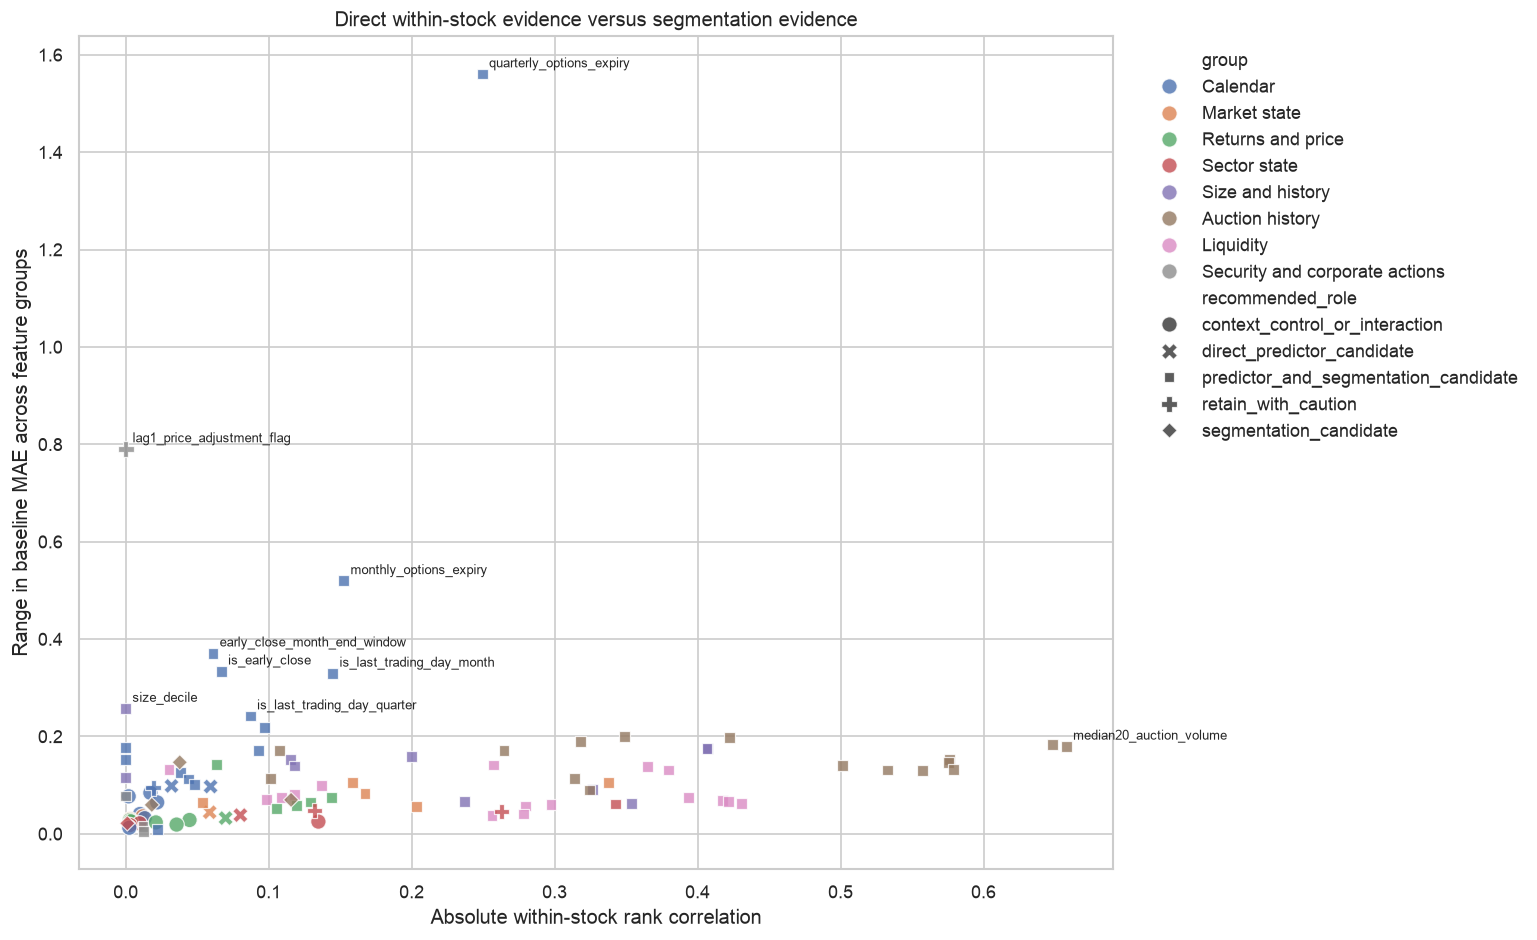

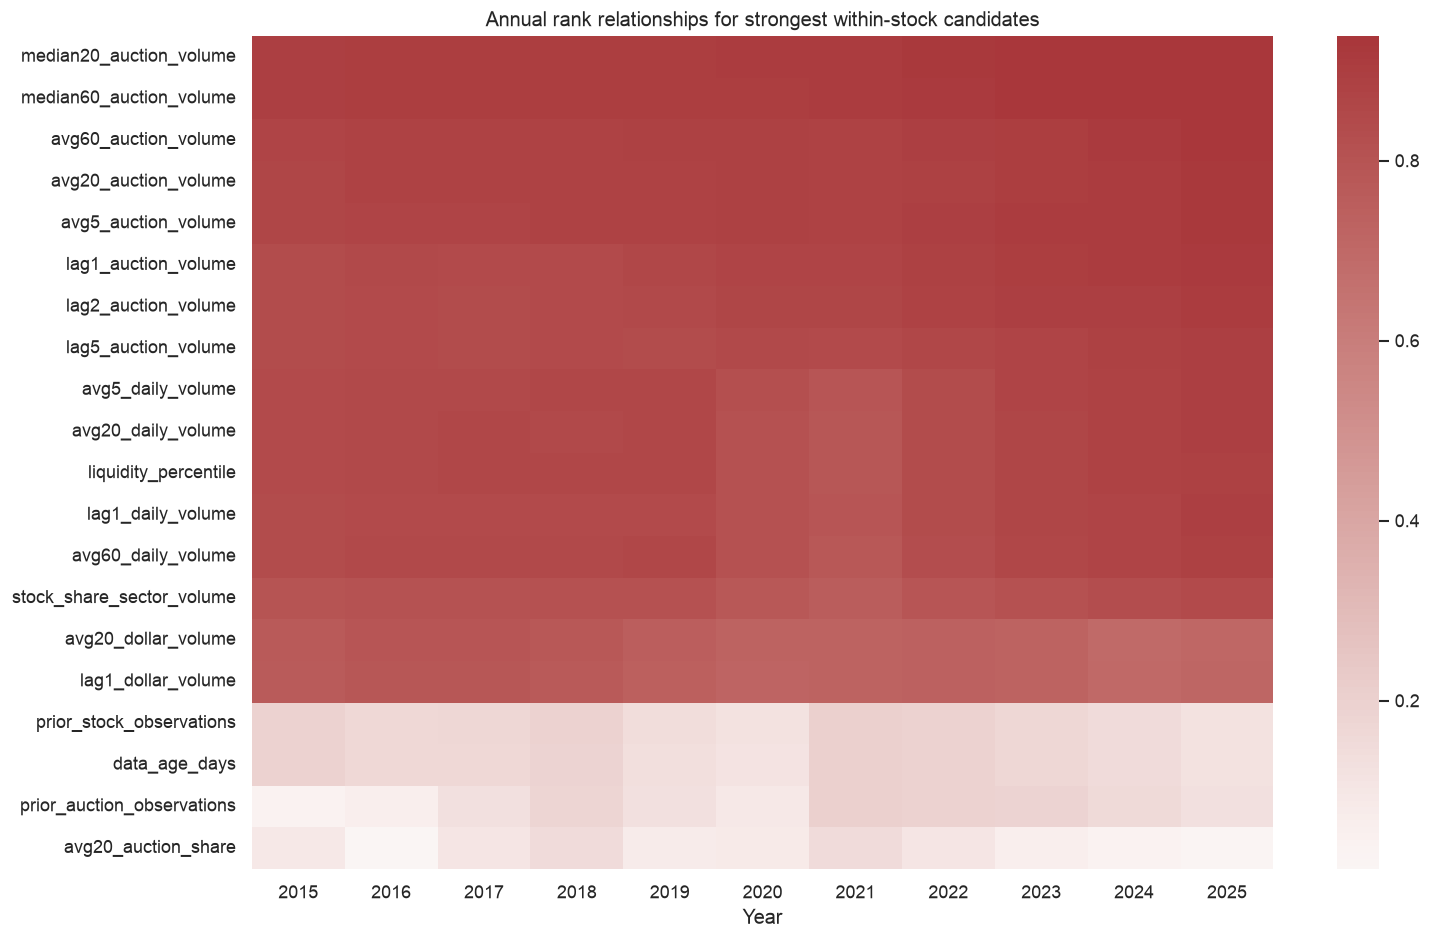

In [8]:
plot = validation.copy()
plot["absolute_within_stock"] = plot["within_stock_rank_corr"].abs().fillna(0)

fig, ax = plt.subplots(figsize=(13, 8))
sns.scatterplot(
    data=plot, x="absolute_within_stock", y="baseline_mae_range",
    hue="group", style="recommended_role", s=85, alpha=0.8, ax=ax,
)
label_candidates = pd.concat([
    plot.nlargest(1, "absolute_within_stock"),
    plot.nlargest(8, "baseline_mae_range"),
]).drop_duplicates("variable")
for _, row in label_candidates.iterrows():
    ax.annotate(row["variable"], (row["absolute_within_stock"], row["baseline_mae_range"]),
                xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set(
    title="Direct within-stock evidence versus segmentation evidence",
    xlabel="Absolute within-stock rank correlation",
    ylabel="Range in baseline MAE across feature groups",
)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(OUT / "prediction_vs_segmentation_evidence.png", bbox_inches="tight")
plt.show()

top_features = validation.assign(
    absolute_within=validation["within_stock_rank_corr"].abs()
).nlargest(20, "absolute_within", keep="all")["variable"].tolist()
heat = annual[annual["feature"].isin(top_features)].pivot(
    index="feature", columns="year", values="rank_correlation"
)
heat = heat.loc[heat.abs().mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(13, 8))
sns.heatmap(heat, cmap="vlag", center=0, ax=ax)
ax.set(title="Annual rank relationships for strongest within-stock candidates", xlabel="Year", ylabel="")
fig.tight_layout()
fig.savefig(OUT / "annual_relationship_stability.png", bbox_inches="tight")
plt.show()

## Conclusions and handoff

This audit preserves the complete feature set. The role labels guide—not dictate—the next experiments. In particular:

- weak standalone features remain available for interactions and bifurcation;
- segmentation candidates must still pass training-only cutoff stability and out-of-time performance tests;
- correlated variables remain in the master panel, although individual model pipelines may regularize or select among them;
- transformations, clipping, imputation, and encoding must be fitted inside each training window.

In [9]:
role_summary = validation.groupby("recommended_role").agg(
    features=("variable", "size"),
    median_absolute_within=("within_stock_rank_corr", lambda s: s.abs().median()),
    median_baseline_mae_range=("baseline_mae_range", "median"),
).reset_index()
display(role_summary)
role_summary.to_csv(OUT / "role_summary.csv", index=False)

print("No features dropped.")
print(f"Retained master features: {validation.retain_in_master_panel.sum()} / {len(validation)}")
print(f"Direct-prediction evidence: {validation.direct_prediction_evidence.sum()}")
print(f"Segmentation evidence: {validation.segmentation_evidence.sum()}")
print(f"Quality cautions: {validation.quality_caution.sum()}")

,recommended_role,features,median_absolute_within,median_baseline_mae_range
0,context_control_or_interaction,16,0.0109,0.0282
1,direct_predictor_candidate,5,0.0593,0.0443
2,predictor_and_segmentation_candidate,70,0.2371,0.1207
3,retain_with_caution,4,0.0757,0.0712
4,segmentation_candidate,4,0.0280,0.0646


No features dropped.
Retained master features: 99 / 99
Direct-prediction evidence: 75
Segmentation evidence: 75
Quality cautions: 4
